In [4]:
!pip install -q langchain-groq

In [5]:
import os
from google.colab import userdata
from langchain_groq import ChatGroq

try:
    os.environ["GROQ_API_KEY"] = userdata.get("GROK_API_KEY")
except Exception:
    print("Please add GROK_API_KEY to your Colab Secrets.")
    raise

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0
)

In [6]:
from typing import Literal
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langchain.agents import create_agent

class FlowerShopState(TypedDict):
    message: str
    intent: str
    reply: str

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy flowers or book bouquets; "
                    "faq = asks about flower prices, availability, timings or policies; "
                    "other = greetings or anything unrelated to the flower shop"
    )

classifier = llm.with_structured_output(Intent)

In [8]:
from langchain_core.tools import tool

@tool
def search_faq(question: str) -> str:
    """Answer frequently asked questions about the flower shop."""

    faqs = {
        "delivery": "We offer local flower delivery.",
        "custom": "Customized bouquets are available.",
        "order": "Advance booking is available.",
        "payment": "We accept cash and UPI payments."
    }

    for key, answer in faqs.items():
        if key in question.lower():
            return answer

    return "I'll check with the owner."

In [10]:
@tool
def get_price(item: str) -> str:
    """Get the price of flowers and bouquets."""
    prices = {
        "rose": 50,
        "lily": 80,
        "bouquet": 500
    }
    price = prices.get(item.lower())
    return f"Rs. {price}" if price is not None else "Item not available."

@tool
def is_open(day: str) -> str:
    """Check flower shop opening timings."""
    return "Open from 9 AM to 8 PM every day."

orders = []

@tool
def log_order(name: str, item: str, quantity: int, pickup_date: str) -> str:
    """Save a customer's flower order."""
    orders.append({
        "name": name,
        "item": item,
        "quantity": quantity,
        "pickup_date": pickup_date
    })
    return "Order saved successfully."

In [11]:
FAQ_PROMPT = """You answer questions for a Flower Shop.
Use get_price for flower and bouquet prices, is_open for timings
and search_faq for policies. Never guess.
If the answer isn't found, say "I'll check with the owner."
Under 50 words."""

ORDER_PROMPT = """You take flower and bouquet orders for a Flower Shop.
Use get_price for totals. Before log_order, make sure you have
name, item, quantity and pickup date; ask for anything missing.
After saving, read the order back. Under 60 words."""

faq_agent = create_agent(
    model=llm,
    tools=[search_faq, get_price, is_open],
    system_prompt=FAQ_PROMPT
)

order_agent = create_agent(
    model=llm,
    tools=[get_price, log_order],
    system_prompt=ORDER_PROMPT
)

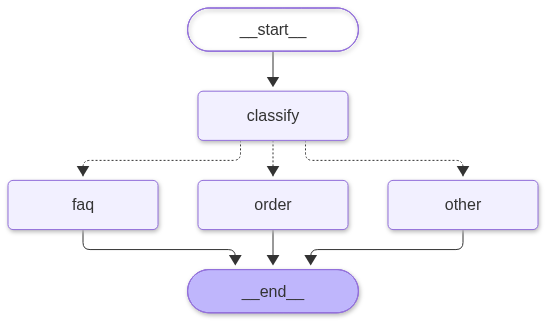

In [12]:
def classify(state: FlowerShopState) -> dict:
    return {"intent": classifier.invoke(state["message"]).intent}

def ask_agent(agent, message: str) -> str:
    result = agent.invoke({
        "messages": [{"role": "user", "content": message}]
    })
    return result["messages"][-1].content

def answer_faq(state: FlowerShopState) -> dict:
    return {"reply": ask_agent(faq_agent, state["message"])}

def take_order(state: FlowerShopState) -> dict:
    return {"reply": ask_agent(order_agent, state["message"])}

def other(state: FlowerShopState) -> dict:
    return {"reply": "Hello from our Flower Shop! I can help with flowers, bouquets, prices, orders and our policies."}

def route(state: FlowerShopState) -> str:
    return state["intent"]

builder = StateGraph(FlowerShopState)

builder.add_node("classify", classify)
builder.add_node("faq", answer_faq)
builder.add_node("order", take_order)
builder.add_node("other", other)

builder.add_edge(START, "classify")

builder.add_conditional_edges(
    "classify", route,
    {"order": "order", "faq": "faq", "other": "other"}
)

builder.add_edge("faq", END)
builder.add_edge("order", END)
builder.add_edge("other", END)

graph = builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [13]:
tests = [
    "Do you deliver flowers to my area?",
    "I'm Ravi, book 2 bouquets for 24 Dec 2026",
    "Good morning!",
    "Do you provide customized bouquets?"
]

for msg in tests:
    print("\nCustomer:", msg)
    for step in graph.stream(
        {"message": msg},
        stream_mode="updates"
    ):
        print("  ", step)


Customer: Do you deliver flowers to my area?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Yes! We offer local flower delivery to your area.'}}

Customer: I'm Ravi, book 2 bouquets for 24 Dec 2026
   {'classify': {'intent': 'order'}}
   {'order': {'reply': 'Ravi, your order for 2 bouquets (pickup on 24\u202fDec\u202f2026) is confirmed. Total cost: Rs\u202f1,000. Thank you!'}}

Customer: Good morning!
   {'classify': {'intent': 'other'}}
   {'other': {'reply': 'Hello from our Flower Shop! I can help with flowers, bouquets, prices, orders and our policies.'}}

Customer: Do you provide customized bouquets?
   {'classify': {'intent': 'faq'}}
   {'faq': {'reply': 'Yes! We offer customized bouquets tailored to your preferences. Let us know the flowers, colors, and style you’d like, and we’ll create a beautiful arrangement just for you.'}}
